# 15 – Phase 5a: noisy labels (training-side filter, validation unchanged)

**Question:** does training *without* the images whose label is probably wrong improve the model?

**What we know so far:**
- In the EDA, 126 training images were flagged `review`: a simple model (linear probe) confidently disagreed with their label.
- Fatemeh's V4 agrees with those labels only ~44% of the time (88% elsewhere). Part of this is by construction, though: the images were *chosen* because a model disagreed.
- Her "0.859 → 0.879" only **excluded them from the evaluation**, so it is not a measured gain.

The real effect of cleaning the *training* set has never been measured. That is what this notebook does.

**Two rules to keep the measurement honest:**
1. **The validation never changes.** Every run is evaluated on all 2,995 images with their original labels, on both validations, exactly like every previous run. If a validation label is wrong, a better model is *penalised* on it, so this measurement can only be pessimistic, never inflated.
2. **No information from the validation fold reaches the filter.** For each outer fold k, the images to drop are chosen by a cross-validation **inside its training part only** (nested CV):
   - the 2,396 training images of fold k are split into 5 inner folds;
   - a model trained on 4 of them predicts the 5th;
   - so every training image gets an out-of-fold probability from a model that never saw it, nor any image of the validation fold k.

   The EDA `review` flags cannot be used directly, because they were computed with *all* images, including the validation images of each fold.

**The flagger.** It is the reference ConvNeXt-Tiny, trained shorter to save time: 12 epochs, batch 64. This is enough, because the baseline plateaued around epoch 10–12. It is much stronger than the EDA linear probe (OOF F1 ≈ 0.85 vs ≈ 0.62), so its disagreements are more meaningful.

An image is **flagged** when the model **confidently** disagrees:
- probability of the given label < 0.1;
- probability of the predicted class > 0.6.

It costs 5 outer × 5 inner = 25 short trainings (≈ 30 min), computed once and cached.

**Runs** (everything else identical to `ref_256` of notebook 14):

| run | flagged training images | idea |
|---|---|---|
| `ref_256` | kept (weight 1), already trained | reference |
| `lbl_drop` | removed (weight 0) | a wrong label teaches the wrong thing: remove it |
| `lbl_down` | kept with weight 0.3 | softer: if the flag is wrong (a hard but correct image), it is not lost entirely |

Relabelling flagged images with the predicted class is **not** tested: if the flagger is wrong, the model would learn the error with full confidence.

**Decision rule:** as in notebook 14, adopt only if the OOF F1 rises by **≳ 0.01**, the clean validation does not drop, and cigar does not collapse. The run-to-run noise is up to ±0.02 on a single fold and a few thousandths on the OOF.

**Time:** ≈ 30 min (flagger) + 2 × 16 min ≈ **1 h 05 min**. Run it in `tmux` from the VS Code terminal:
```
tmux new -s phase5a
cd ~/ANN-DL-Challenge/families/elia && source ../../.venv/bin/activate
jupyter nbconvert --to notebook --execute --inplace --ExecutePreprocessor.timeout=-1 15_phase5a_label_noise.ipynb
```

## 0. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score

import train_lib as T
import common as C

plt.rcParams["figure.dpi"] = 80
SMOKE_TEST = False          # True = tiny run (few images, 1 epoch) only to check that the code works
data = T.load_data(smoke_test=SMOKE_TEST)
REF = "ref_256"             # trained in notebook 14
print("device:", T.DEVICE, "| outputs:", T.OUT_DIR)
assert SMOKE_TEST or (T.OUT_DIR / REF / "oof.csv").exists(), "run notebook 14 first (ref_256)"

loaded 2995 training images (+ shifted versions) in 6s
device: cuda | outputs: /home/elia/ANN-DL-Challenge/families/elia/outputs


## 1. Find the likely wrong labels (nested cross-validation)

`T.find_label_issues` trains 25 short models and saves `outputs/label_flags/flags.csv`. The file has one row per (outer fold, training image), with:
- the given label;
- the predicted class;
- the two probabilities;
- the flag.

Each image appears in 4 outer folds (it is a training image in all folds except its own), and can be flagged in some of them and not in others.

In [2]:
FLAG_NAME = "label_flags_SMOKE" if SMOKE_TEST else "label_flags"
flag_cfg = T.reference_config(run_name=FLAG_NAME, epochs=1 if SMOKE_TEST else 12, batch_size=16 if SMOKE_TEST else 64)
flags = T.find_label_issues(flag_cfg, data, name=FLAG_NAME)
FLAGS_PATH = str(T.OUT_DIR / FLAG_NAME / "flags.csv")

label_flags: already computed, loading /home/elia/ANN-DL-Challenge/families/elia/outputs/label_flags/flags.csv


## 2. What the filter found

How many images are flagged, in which classes, and towards which predicted class? Overlap with the EDA `review` flags: they come from a different, weaker model on all the data, so a large overlap means that two independent models agree that those labels are suspicious.

In [3]:
per_fold = flags.groupby("outer_fold").agg(training_images=("id", "size"), flagged=("flagged", "sum"))
per_fold["inner_oof_accuracy"] = (flags.pred == flags.label).groupby(flags.outer_fold).mean()
per_fold["flagged %"] = 100 * per_fold.flagged / per_fold.training_images
display(per_fold.round(3))

# an image is "ever flagged" if flagged in at least one outer fold, "always flagged" if in all its outer folds
img = flags.groupby("id").agg(label=("label", "first"), times=("flagged", "sum"), n=("flagged", "size"))
ever, always = img[img.times > 0], img[img.times == img.n]
review_ids = set(data["folds"].id[data["folds"].review.astype(bool)])
print(f"images flagged in at least one outer fold: {len(ever)}  | in all of their outer folds: {len(always)}")
print(f"EDA review images: {len(review_ids)}  | of which flagged at least once here: {len(review_ids & set(ever.index))}")

,training_images,flagged,inner_oof_accuracy,flagged %
outer_fold,,,,
0,2396,100,0.834,4.174
1,2396,91,0.831,3.798
2,2396,104,0.835,4.341
3,2396,93,0.827,3.881
4,2396,91,0.837,3.798


images flagged in at least one outer fold: 193  | in all of their outer folds: 64
EDA review images: 126  | of which flagged at least once here: 52


> **Comment: the filter.**
> - **A strong flagger.** The inner models reach **0.83–0.84 accuracy** out-of-fold, despite seeing only 1,917 images for 12 epochs. This is far stronger than the EDA linear probe (≈ 0.6).
> - **About 4% of each training set is flagged:** 91–104 images out of 2,396 per outer fold.
> - **193 different images** are flagged at least once, and **64** in all four outer folds where they are training images. The 64 are the most robust candidates: four independent filters, each trained on different data, agree on them.
> - **Overlap with the EDA `review` flags: 52 of 126.** Two different models agree on less than half of the EDA list. The other 74 `review` images were probably flagged by the weak probe simply because they were hard for it.

In [4]:
# from which class (rows, given label) to which class (columns, predicted) the flagged images go
fl = flags[flags.flagged].drop_duplicates("id")
names = [f"{c} {C.CLASSES[c]}" for c in range(C.N_CLASSES)]
trans = pd.crosstab(fl.label.map(dict(enumerate(names))), fl.pred.map(dict(enumerate(names))))
display(trans)
share = (img.assign(f=img.times > 0).groupby("label").f.mean() * 100).rename(index=dict(enumerate(names)))
print("share of each class flagged at least once (%):"); print(share.round(1).to_string())

pred,0 disturbed,1 merging,2 round smooth,3 in-between smooth,4 cigar,5 barred spiral,6 tight spiral,7 loose spiral,8 edge-on no bulge,9 edge-on bulge
label,,,,,,,,,,
0 disturbed,0,3,11,17,4,10,2,19,0,4
1 merging,1,0,3,3,0,4,0,3,2,1
2 round smooth,0,2,0,1,0,3,4,3,0,0
3 in-between smooth,0,2,1,0,1,0,1,0,0,0
4 cigar,0,0,0,0,0,0,0,0,2,1
5 barred spiral,0,2,2,2,0,0,4,6,0,0
6 tight spiral,0,1,4,3,0,4,0,8,1,0
7 loose spiral,0,5,0,0,0,8,12,0,5,0
8 edge-on no bulge,1,1,0,0,0,1,0,1,0,4


share of each class flagged at least once (%):
label
0 disturbed            38.5
1 merging               5.4
2 round smooth          2.9
3 in-between smooth     1.5
4 cigar                 5.4
5 barred spiral         4.6
6 tight spiral          6.8
7 loose spiral          6.8
8 edge-on no bulge      3.3
9 edge-on bulge         3.2


> **Comment: where the flagged images are. Above all, disturbed.**
> - **38.5% of all disturbed images** (70 of 182) are flagged at least once. Every other class is at 1.5–7%.
> - The flagged disturbed images go mostly to:
>   - loose spiral (19);
>   - in-between smooth (17);
>   - round smooth (11);
>   - barred spiral (10).
> - The rest are mostly **boundary cases between neighbouring classes:**
>   - loose ↔ tight spiral (12 + 8);
>   - loose/tight → barred spiral;
>   - edge-on bulge ↔ edge-on no bulge.
>
> This is the same picture as the confusion matrices of notebooks 11–14. The "label noise" is concentrated exactly where the classes are **intrinsically ambiguous**, not spread at random.

### Visual check

24 flagged images: the title shows the **given label → predicted class (its probability)**.

**Check by eye:** in how many of them do you agree with the model rather than with the label? If most look like genuinely wrong labels, the filter is doing its job. If they look like correct but hard or ambiguous galaxies, dropping them could hurt, because the model would lose exactly the hard examples it needs.

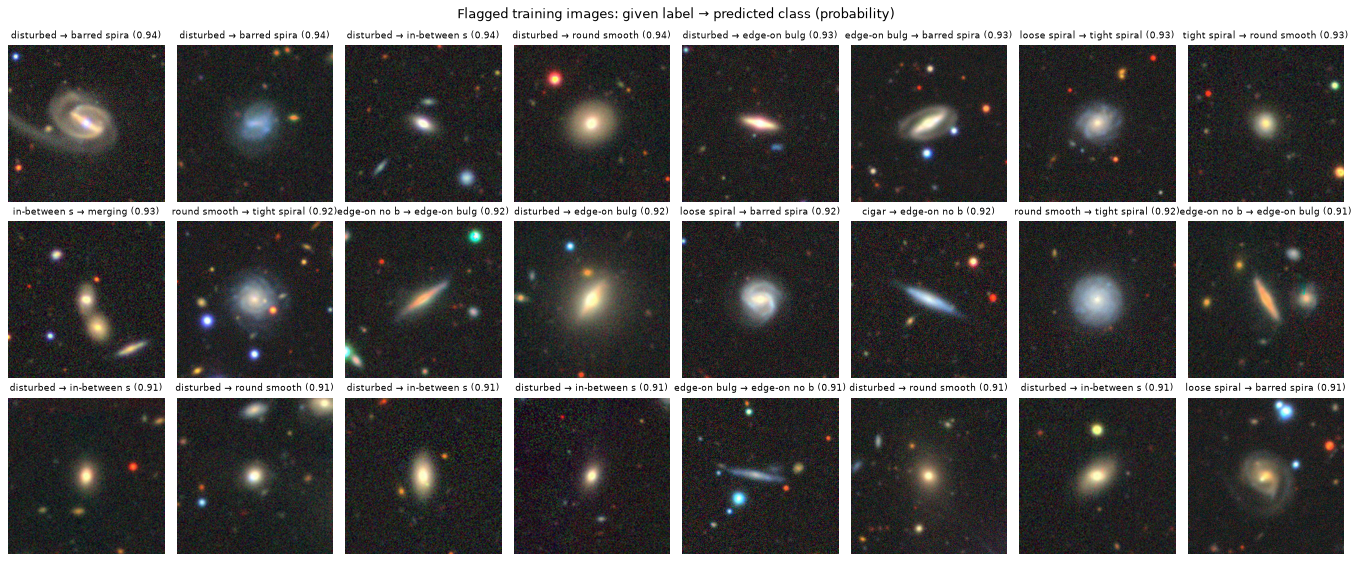

In [5]:
show = fl.sort_values("p_pred", ascending=False).head(24)
pos = pd.Series(np.arange(len(data["folds"])), index=data["folds"].id)
fig, axes = plt.subplots(3, 8, figsize=(17, 7.2))
for ax, (_, r) in zip(axes.ravel(), show.iterrows()):
    ax.imshow(data["X_clean"][pos[r.id]]); ax.axis("off")
    ax.set_title(f"{C.CLASSES[r.label][:12]} → {C.CLASSES[r.pred][:12]} ({r.p_pred:.2f})", fontsize=8)
for ax in axes.ravel()[len(show):]:
    ax.axis("off")
plt.suptitle("Flagged training images: given label → predicted class (probability)"); plt.tight_layout(); plt.show()

> **Comment: visual check (my reading; worth checking by eye too).** The 24 most confident disagreements fall into three groups.
>
> **1. Probably wrong labels:**
> - an `in-between smooth` that shows **two galaxies close together**, i.e. a merging (row 2, column 1);
> - a `cigar` that looks like a thin edge-on disc (row 2, column 6);
> - a few edge-on bulge / no-bulge swaps.
>
> **2. Ambiguous boundary cases:** tight vs loose spiral, and loose vs barred spiral, where even a human would hesitate.
>
> **3. `disturbed` galaxies that look like ordinary smooth ellipticals** (most of row 3). This is the important group. "Disturbed" means that the galaxy has been distorted by an interaction, and the sign is often a **faint tidal tail or asymmetry**, barely visible at this contrast. Some images in the grid show it if you look closely, e.g. the barred spiral with a tail on its left (row 1, column 1).
>
> For this third group the label is plausibly **correct but hard**: the model does not see the faint feature, so it calls them smooth. Removing them from training means removing the hardest *correct* examples of disturbed, the ones the model most needs to learn the class.

## 3. Train without (or down-weighting) the flagged images

In [6]:
EXPERIMENTS = [
    T.reference_config(run_name="lbl_drop", note="ref_256 - flagged labels removed from training (nested CV)",
                       label_flags=FLAGS_PATH, flag_weight=0.0),
    T.reference_config(run_name="lbl_down", note="ref_256 - flagged labels down-weighted to 0.3 (nested CV)",
                       label_flags=FLAGS_PATH, flag_weight=0.3),
]
if SMOKE_TEST:
    for cfg in EXPERIMENTS:
        cfg.update(run_name=cfg["run_name"] + "_SMOKE", epochs=1, folds=[0], batch_size=16)
results = {}
for cfg in EXPERIMENTS:
    results[cfg["run_name"]] = T.run_experiment(cfg, data)

lbl_drop: already done, loading results
lbl_down: already done, loading results


## 4. Comparison with `ref_256` (full validation, original labels)

This is the comparison that decides: same 2,995 validation images, same labels, both validations.

In [7]:
RUNS = [cfg["run_name"] for cfg in EXPERIMENTS]
table = T.compare(RUNS, reference=REF)
table.style.format("{:.4f}").background_gradient(subset=["Δ clean", "Δ shifted"], cmap="RdYlGn", vmin=-0.02, vmax=0.02)

,F1 clean,F1 shifted,Δ clean,Δ shifted,gap (clean − shifted),cigar clean,cigar shifted
run,,,,,,,
ref_256,0.8510,0.8452,0.0000,0.0000,0.0057,0.8235,0.8333
lbl_drop,0.8479,0.8431,-0.0031,-0.0022,0.0048,0.8571,0.8621
lbl_down,0.8505,0.8462,-0.0004,0.0010,0.0043,0.8235,0.8333


In [8]:
# fold by fold (paired, same validation images): Δ = run − ref_256
def fold_f1(run, mask=None):
    oof = pd.read_csv(T.OUT_DIR / run / "oof.csv")
    m = np.ones(len(oof), bool) if mask is None else mask
    out = {}
    for val in ["clean", "shifted"]:
        P = oof[[f"p{c}_{val}" for c in range(C.N_CLASSES)]].to_numpy()
        out[val] = [f1_score(oof.label[(oof.fold == k) & m], P[(oof.fold == k) & m].argmax(1), average="weighted")
                    for k in range(5)]
    return out

ref = fold_f1(REF)
rows = []
for run in RUNS:
    if not (T.OUT_DIR / run / "oof.csv").exists():
        continue
    f = fold_f1(run)
    for val in ["clean", "shifted"]:
        d = np.array(f[val]) - np.array(ref[val])
        rows.append({"run": run, "validation": val, **{f"fold {k}": d[k] for k in range(5)},
                     "mean Δ": d.mean(), "folds better": int((d > 0).sum())})
pd.DataFrame(rows).set_index(["run", "validation"]).style.format(
    {**{f"fold {k}": "{:+.4f}" for k in range(5)}, "mean Δ": "{:+.4f}"}
).background_gradient(subset=["mean Δ"], cmap="RdYlGn", vmin=-0.02, vmax=0.02)

> **Comment: comparison with `ref_256` — neither filter helps.**
>
> | run | OOF clean (Δ) | OOF shifted (Δ) | folds better (clean / shifted) |
> |---|---|---|---|
> | ref_256 | 0.8510 | 0.8452 | – |
> | lbl_drop | 0.8479 (−0.003) | 0.8431 (−0.002) | 2/5, 1/5 |
> | lbl_down | 0.8505 (−0.0004) | 0.8462 (+0.001) | 3/5, 4/5 |
>
> - **Removing** the flagged images is slightly *worse*, on most folds of both validations.
> - **Down-weighting** them is equal to the reference.
>
> Both differences are within the run-to-run noise measured in notebook 14 (a few thousandths on the OOF, up to ±0.02 on a single fold).

In [9]:
names_runs = [REF] + RUNS
for val in ["clean", "shifted"]:
    t = T.per_class(names_runs, val)
    d = t.sub(t[REF], axis=0).drop(columns=REF)
    print(f"{val.upper()} validation: per-class F1 of {REF}, then Δ")
    display(pd.concat([t[[REF]], d], axis=1).style.format("{:+.3f}").format("{:.3f}", subset=[REF])
            .background_gradient(subset=list(d.columns), cmap="RdYlGn", vmin=-0.05, vmax=0.05))

CLEAN validation: per-class F1 of ref_256, then Δ


,ref_256,lbl_drop,lbl_down
0 disturbed,0.513,-0.064,-0.029
1 merging,0.895,+0.010,+0.010
2 round smooth,0.933,-0.007,-0.002
3 in-between smooth,0.927,-0.007,-0.007
4 cigar,0.824,+0.034,+0.000
5 barred spiral,0.869,-0.013,-0.009
6 tight spiral,0.782,+0.011,+0.009
7 loose spiral,0.745,+0.005,+0.004
8 edge-on no bulge,0.925,+0.009,+0.009
9 edge-on bulge,0.948,-0.000,+0.003


SHIFTED validation: per-class F1 of ref_256, then Δ


,ref_256,lbl_drop,lbl_down
0 disturbed,0.482,-0.036,-0.023
1 merging,0.883,+0.015,+0.013
2 round smooth,0.934,-0.007,-0.003
3 in-between smooth,0.926,-0.011,-0.009
4 cigar,0.833,+0.029,+0.000
5 barred spiral,0.858,-0.010,+0.002
6 tight spiral,0.786,-0.000,+0.002
7 loose spiral,0.737,+0.003,+0.006
8 edge-on no bulge,0.924,+0.010,+0.008
9 edge-on bulge,0.943,+0.001,+0.004


> **Comment: per class, the cost falls on disturbed.**
>
> | class | `lbl_drop` (clean / shifted) | `lbl_down` (clean / shifted) |
> |---|---|---|
> | disturbed | **−0.064 / −0.036** | −0.029 / −0.023 |
> | cigar | **+0.034 / +0.029** | 0 |
> | merging | +0.010 / +0.015 | ≈ +0.01 |
> | edge-on no bulge | +0.009 / +0.010 | ≈ +0.01 |
>
> For **disturbed**, removing 38% of its training images (most of the flagged ones) teaches the model that disturbed is rarer and "cleaner" than it really is. So it predicts the class less, and its F1 drops. This confirms the reading of the visual check: many flagged disturbed labels were correct, just hard.
>
> For **cigar** (+0.03), the 3 flagged cigars were probably edge-on discs, and removing them helps. But cigar has only ~56 images, so this is 1–2 images.
>
> Merging and the edge-on classes gain ≈ +0.01. Weighted F1 still drops, because disturbed weighs more (6% of the data).

## 5. For information only: F1 on the "unsuspicious" validation images

The same OOF predictions, scored after **excluding from the evaluation** the validation images whose labels are suspicious (the EDA `review` images). This is **not** used for the decision. It removes hard images from the calculation for every model alike, which inflates all the scores.

It only answers a side question: is the gain or loss of the filtered models concentrated on the doubtful images, or spread over the normal ones?

In [10]:
rows = []
for run in [REF] + RUNS:
    if not (T.OUT_DIR / run / "oof.csv").exists():
        continue
    oof = pd.read_csv(T.OUT_DIR / run / "oof.csv")
    normal = ~oof.id.isin(review_ids).to_numpy()      # per run: smoke runs cover fewer images
    for val in ["clean", "shifted"]:
        P = oof[[f"p{c}_{val}" for c in range(C.N_CLASSES)]].to_numpy().argmax(1)
        rows.append({"run": run, "validation": val,
                     "F1 all images": f1_score(oof.label, P, average="weighted"),
                     "F1 without review images": f1_score(oof.label[normal], P[normal], average="weighted"),
                     "accuracy on review images": (oof.label[~normal] == P[~normal]).mean()})
pd.DataFrame(rows).set_index(["run", "validation"]).round(4)

F1 all images  F1 without review images  \
run      validation                                            
ref_256  clean              0.8510                    0.8701   
         shifted            0.8452                    0.8640   
lbl_drop clean              0.8479                    0.8686   
         shifted            0.8431                    0.8636   
lbl_down clean              0.8505                    0.8703   
         shifted            0.8462                    0.8652   

                     accuracy on review images  
run      validation                             
ref_256  clean                          0.4524  
         shifted                        0.4603  
lbl_drop clean                          0.4286  
         shifted                        0.4286  
lbl_down clean                          0.4444  
         shifted                        0.4603

> **Comment: the doubtful validation images do not change.**
> - Accuracy on the 126 `review` validation images is **0.43–0.46 for all three runs**.
> - The F1 without them is **0.869–0.870 for all three**.
>
> Cleaning the training set does not make the model agree more with those labels, and it does not improve the normal images either. Note that all three runs gain ≈ +0.02 here, just from excluding hard images from the calculation. This is exactly the evaluation-only effect that was mistaken for a real gain earlier (Fatemeh's 0.859 → 0.879), and it is why this table is not used to decide.

## 6. Decision

| run | F1 clean (Δ) | F1 shifted (Δ) | folds better (clean / shifted) | verdict |
|---|---|---|---|---|
| lbl_drop | 0.8479 (−0.003) | 0.8431 (−0.002) | 2/5, 1/5 | ✗ slightly worse; hurts disturbed (−0.06 / −0.04) |
| lbl_down | 0.8505 (−0.0004) | 0.8462 (+0.001) | 3/5, 4/5 | ✗ no effect |

- **Flagged images:**
  - per fold: 91–104 (≈ 4%);
  - 193 distinct images, 64 flagged in every outer fold;
  - overlap with the EDA `review` images: 52 of 126.
- **Visual check:** a minority of genuinely wrong labels (e.g. a merging labelled in-between smooth). Most flagged images are boundary cases, or `disturbed` galaxies whose distinguishing feature (a faint tidal tail) is hard to see, i.e. probably correct labels.
- **Decision:** the label filter is **not adopted**; `ref_256` stays the reference. The original training labels are kept, and label smoothing 0.1 already limits the influence of the few wrong ones.

**What we learn.**
1. The "noisy labels" of this dataset are mostly **class ambiguity**, not random mistakes. They are concentrated in disturbed (38% of the class flagged) and at the spiral boundaries. A filter cannot separate "wrong" from "hard", and removing hard examples hurts.
2. This also explains the **ceiling at ≈ 0.85**:
   - disturbed (F1 ≈ 0.5, 6% of the data) and the spiral boundaries cost most of the remaining error;
   - neither augmentation (notebooks 11 and 13), resolution (14) nor label cleaning (15) moves them.
3. Like the previous phases, this is a useful **negative result for the report**: measured with an unchanged validation and nested CV, cleaning the labels does not help. Most of the apparent gain (0.859 → 0.879) was an evaluation artifact.

**Next options:**
- a model with more capacity (ConvNeXt-Small, phase 5b), still one change at a time against `ref_256`;
- an ensemble with genuinely different models, e.g. Davide's EfficientNetV2-S.